# Figure 3 Supplement 6: Conditional accuracy functions

The conditional accuracy function (CAF): the probability that a decision made
at decision time DT is correct, P(correct | DT). Trial-to-trial variability in
drift rate makes the CAF fall (slow decisions are enriched for hard trials);
trial-to-trial variability in the bound flattens it or makes it rise; a bound
that collapses within the trial makes it fall (later decisions are made on
less evidence). The stopping model has all three ingredients at each subject's
fitted values, so the question is whether, together, they reproduce the CAF's
shape without any further fitting.

Each panel: the data pooled across subjects (black points, 50% Clopper–Pearson
intervals) and the same quantity from data simulated from each subject's
stopping-model fit (`SIM_REPS` repetitions of the subject's real trials,
measured with the same pipeline; dashed blue). P value: paired Wilcoxon test of
each subject's CAF slope (linear regression of correct on DT over `DT_VALS`),
data vs. model.

Rows: cohort 1 (OL, blocked SNR) and cohort 2 (MX, mixed SNR, both SNRs pooled,
so drift varies from trial to trial by design). Columns: blocks 1–3 (low SNR
in cohort 1). Trials: the standard filter (`get_good_trial_array`: DT ≥ 2,
trial_number ≥ 10 and the adaptation exclusion, no wall hit, RT cutoff), finite
nonzero bound. Subject-blocks whose plateau sits at a fit limit are left out
(counts printed).

Replaces the old Figure03S06 (`notebooks/archive/Figure03S06_conditionalAccuracy.ipynb`),
which fit a shared bound SD to each panel's CAF.


In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.data import get_good_trial_array
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import DATA_COLOR, FONT_RC, MODEL_COLOR, add_panel_label, format_p
from pigeon.stopping import (get_plateau_at_limit, get_stopping_model_trials, infer_bounds_like_data,
                             simulate_stopping_data_table)

PROCESSED = Path('../data/processed')

In [2]:
SIM_REPS = 20
SIM_SEED = 15
DT_VALS = np.arange(2, 11)
MIN_SLOPE_TRIALS = 10
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {'B1': 'No penalty', 'B2': 'Coin penalty', 'B3': 'Step penalty'}
ROWS = {'OL': 'Cohort 1\n(blocked SNR)', 'MX': 'Cohort 2\n(mixed SNR)'}

fits_all = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
rng = np.random.default_rng(SIM_SEED)
data, model = {}, {}
for task, blocks in {'OL': [1, 2, 3, 4, 5, 6], 'MX': [1, 2, 3]}.items():
    t = get_stopping_model_trials(task, blocks)
    t = t[t.condition.isin(BLOCKS)].copy()
    f = fits_all[(fits_all.task == task) & fits_all.group.isin(BLOCKS)]
    lim = f.loc[get_plateau_at_limit(f), ['subject_index', 'group']]
    print(f'{task}: excluded {len(lim)} subject-blocks with the plateau at a fit limit: '
          f'{list(map(tuple, lim.to_numpy()))}')
    f = f[~get_plateau_at_limit(f)]
    t = t.merge(f[['subject_index', 'group']], left_on=['subject_index', 'condition'],
                right_on=['subject_index', 'group']).drop(columns='group')
    s = infer_bounds_like_data(simulate_stopping_data_table(t, f, group_col='condition', num_reps=SIM_REPS,
                                                            rng=rng))
    for out, d in ((data, t), (model, s)):
        lg = get_good_trial_array(d, min_dt=2) & np.isfinite(d.bound) & (d.bound != 0) & d.DT.isin(DT_VALS)
        out[task] = d.loc[lg, ['subject_index', 'condition', 'DT', 'correct']]
    print(f'{task}: {len(data[task])} real and {len(model[task])} simulated trials at DT {DT_VALS[0]}-{DT_VALS[-1]}')

def _caf(d):
    g = d.groupby('DT').correct
    return g.sum().reindex(DT_VALS, fill_value=0), g.size().reindex(DT_VALS, fill_value=0)

def _slopes(d):
    def one(x):
        return scipy.stats.linregress(x.DT, x.correct).slope if len(x) >= MIN_SLOPE_TRIALS and x.DT.nunique() > 1 \
            else np.nan
    return d.groupby('subject_index')[['DT', 'correct']].apply(one)

rows, cafs = [], {}
for task in ROWS:
    for b in BLOCKS:
        dd, mm = data[task][data[task].condition == b], model[task][model[task].condition == b]
        cafs[task, b] = (_caf(dd), _caf(mm))
        sl = pd.DataFrame({'data': _slopes(dd), 'model': _slopes(mm)}).dropna()
        p = scipy.stats.wilcoxon(sl.data, sl.model).pvalue
        rows.append({'task': task, 'block': b, 'trials': len(dd), 'subjects (slopes)': len(sl),
                     'slope per step, data median': sl.data.median(), 'model median': sl.model.median(),
                     'pooled accuracy data': dd.correct.mean(), 'model': mm.correct.mean(), 'Wilcoxon p': p})
summary = pd.DataFrame(rows).set_index(['task', 'block'])
display(summary.round(4))

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects
OL: excluded 5 subject-blocks with the plateau at a fit limit: [(13, 'B3'), (44, 'B3'), (51, 'B1'), (51, 'B2'), (59, 'B1')]


OL: 7215 real and 141958 simulated trials at DT 2-10


MX: subjects with a good adaptation tau fit, by block: {1: 3, 2: 15, 3: 11}
MX: 18,726 trials in blocks [1, 2, 3]; excluded 1,620 with trial_number < 10, 58 more in the adaptation transient, 182 more with no choice; 60 subjects
MX: excluded 8 subject-blocks with the plateau at a fit limit: [(18, 'B1'), (18, 'B2'), (18, 'B3'), (28, 'B3'), (42, 'B3'), (45, 'B1'), (53, 'B2'), (54, 'B2')]


MX: 8076 real and 163312 simulated trials at DT 2-10


trials  subjects (slopes)  slope per step, data median  \
task block                                                           
OL   B1       3453                 54                       0.0012   
     B2       2502                 53                       0.0021   
     B3       1260                 47                      -0.0004   
MX   B1       3355                 56                      -0.0066   
     B2       3169                 57                      -0.0179   
     B3       1552                 48                      -0.0202   

            model median  pooled accuracy data   model  Wilcoxon p  
task block                                                          
OL   B1           0.0036                0.7173  0.7043      0.7338  
     B2           0.0023                0.7398  0.7551      0.7399  
     B3          -0.0016                0.7817  0.7677      0.9124  
MX   B1          -0.0118                0.7851  0.7860      0.7014  
     B2          -0.0122                0.8321  0.8287      0.1166  
     B3          -0.0149                0.8305  0.8329      0.6076

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


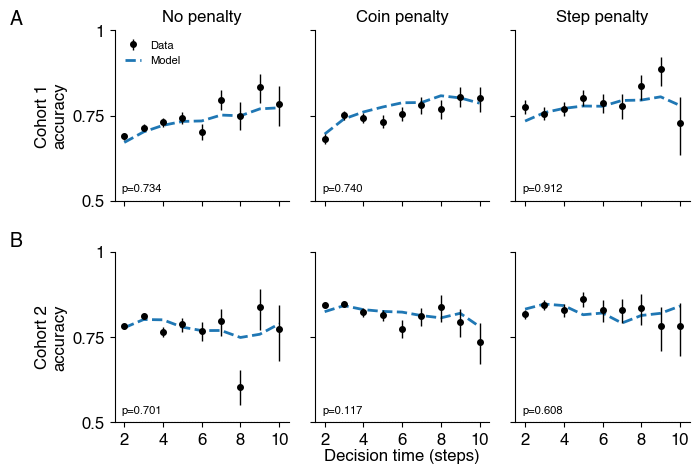

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S06.pdf (+ .png)


In [3]:
CM = 1 / 2.54
FS = 12
FS_INSET = 8
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, 'xtick.labelsize': FS,
                     'ytick.labelsize': FS, **FONT_RC})
MODEL = MODEL_COLOR
ROW_LABELS = {'OL': 'Cohort 1', 'MX': 'Cohort 2'}
YLIM = (0.5, 1.0)

def _ci(k, n, ci=0.5):
    lo = scipy.stats.beta.ppf((1 - ci) / 2, k, n - k + 1)
    hi = scipy.stats.beta.ppf(1 - (1 - ci) / 2, k + 1, n - k)
    return np.nan_to_num(lo, nan=0.0), np.nan_to_num(hi, nan=1.0)

fig = plt.figure(figsize=(17.6 * CM, 12 * CM))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.3, wspace=0.15, left=0.15, right=0.98, bottom=0.1, top=0.93)
axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(2)])
for r, task in enumerate(ROWS):
    for c, b in enumerate(BLOCKS):
        ax = axes[r, c]
        (kd, nd), (km, nm) = cafs[task, b]
        ok = nd > 0
        acc = kd[ok] / nd[ok]
        lo, hi = _ci(kd[ok].to_numpy(), nd[ok].to_numpy())
        ax.axhline(0.5, color='0.5', ls=':', lw=0.8)
        ax.plot(DT_VALS[nm > 0], (km / nm)[nm > 0], '--', color=MODEL, lw=2, label='Model')
        ax.errorbar(acc.index, acc, yerr=[acc - lo, hi - acc], fmt='o', color=DATA_COLOR, ms=4, elinewidth=1, capsize=0,
                    label='Data')
        if (acc < YLIM[0]).any():
            print(f'{task} {b}: accuracy below {YLIM[0]} at DT {list(acc.index[acc < YLIM[0]])} (off the axis)')
        p = summary.loc[(task, b), 'Wilcoxon p']
        ax.text(0.04, 0.04, format_p(p), transform=ax.transAxes, ha='left', va='bottom', fontsize=FS_INSET)
        ax.set_xlim(DT_VALS[0] - 0.5, DT_VALS[-1] + 0.5)
        ax.set_xticks(DT_VALS[::2])
        ax.set_ylim(YLIM)
        ax.set_yticks([0.5, 0.75, 1], ['0.5', '0.75', '1'])
        if r == 0:
            ax.set_title(BLOCK_TITLES[b])
            ax.set_xticklabels([])
        if c > 0:
            ax.set_yticklabels([])
        else:
            ax.set_ylabel(f'{ROW_LABELS[task]}\naccuracy')
        ax.spines[['top', 'right']].set_visible(False)

h, l = axes[0, 0].get_legend_handles_labels()
axes[0, 0].legend(h[::-1], l[::-1], fontsize=FS_INSET, frameon=False, loc='upper left', handlelength=1.5)
fig.canvas.draw()
left, right = axes[-1, 0].get_position().x0, axes[-1, -1].get_position().x1
bottom = min(a.get_tightbbox().transformed(fig.transFigure.inverted()).y0 for a in axes[-1])
fig.text((left + right) / 2, bottom - 0.004, 'Decision time (steps)', ha='center', va='top', fontsize=FS)
for r, letter in enumerate('AB'):
    add_panel_label(axes[r, 0], letter, dx=-0.6, dy=1.12)

out = FIGURES_DIR / 'Figure03_S06.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)